In [33]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import scipy.stats as stats
import seaborn as sns

In [34]:
sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"] = (10, 6)

In [35]:
# Connexion à Google Drive
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [36]:
# Chargement du fichier
df = pd.read_csv("/content/drive/MyDrive/vente/Sample - Superstore.csv", encoding="latin-1")

In [37]:
# Aperçu des colonnes et des types de données
print("--- Structure des données ---")
print(df.info())

--- Structure des données ---
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 9994 entries, 0 to 9993
Data columns (total 21 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   Row ID         9994 non-null   int64  
 1   Order ID       9994 non-null   object 
 2   Order Date     9994 non-null   object 
 3   Ship Date      9994 non-null   object 
 4   Ship Mode      9994 non-null   object 
 5   Customer ID    9994 non-null   object 
 6   Customer Name  9994 non-null   object 
 7   Segment        9994 non-null   object 
 8   Country        9994 non-null   object 
 9   City           9994 non-null   object 
 10  State          9994 non-null   object 
 11  Postal Code    9994 non-null   int64  
 12  Region         9994 non-null   object 
 13  Product ID     9994 non-null   object 
 14  Category       9994 non-null   object 
 15  Sub-Category   9994 non-null   object 
 16  Product Name   9994 non-null   object 
 17  Sales          9994 no

In [38]:
df.head()

,Row ID,Order ID,Order Date,Ship Date,Ship Mode,Customer ID,Customer Name,Segment,Country,City,...,Postal Code,Region,Product ID,Category,Sub-Category,Product Name,Sales,Quantity,Discount,Profit
0,1,CA-2016-152156,11/8/2016,11/11/2016,Second Class,CG-12520,Claire Gute,Consumer,United States,Henderson,...,42420,South,FUR-BO-10001798,Furniture,Bookcases,Bush Somerset Collection Bookcase,261.9600,2,0.00,41.9136
1,2,CA-2016-152156,11/8/2016,11/11/2016,Second Class,CG-12520,Claire Gute,Consumer,United States,Henderson,...,42420,South,FUR-CH-10000454,Furniture,Chairs,"Hon Deluxe Fabric Upholstered Stacking Chairs,...",731.9400,3,0.00,219.5820
2,3,CA-2016-138688,6/12/2016,6/16/2016,Second Class,DV-13045,Darrin Van Huff,Corporate,United States,Los Angeles,...,90036,West,OFF-LA-10000240,Office Supplies,Labels,Self-Adhesive Address Labels for Typewriters b...,14.6200,2,0.00,6.8714
3,4,US-2015-108966,10/11/2015,10/18/2015,Standard Class,SO-20335,Sean O'Donnell,Consumer,United States,Fort Lauderdale,...,33311,South,FUR-TA-10000577,Furniture,Tables,Bretford CR4500 Series Slim Rectangular Table,957.5775,5,0.45,-383.0310
4,5,US-2015-108966,10/11/2015,10/18/2015,Standard Class,SO-20335,Sean O'Donnell,Consumer,United States,Fort Lauderdale,...,33311,South,OFF-ST-10000760,Office Supplies,Storage,Eldon Fold 'N Roll Cart System,22.3680,2,0.20,2.5164


In [39]:
df.describe()

,Row ID,Postal Code,Sales,Quantity,Discount,Profit
count,9994.000000,9994.000000,9994.000000,9994.000000,9994.000000,9994.000000
mean,4997.500000,55190.379428,229.858001,3.789574,0.156203,28.656896
std,2885.163629,32063.693350,623.245101,2.225110,0.206452,234.260108
min,1.000000,1040.000000,0.444000,1.000000,0.000000,-6599.978000
25%,2499.250000,23223.000000,17.280000,2.000000,0.000000,1.728750
50%,4997.500000,56430.500000,54.490000,3.000000,0.200000,8.666500
75%,7495.750000,90008.000000,209.940000,5.000000,0.200000,29.364000
max,9994.000000,99301.000000,22638.480000,14.000000,0.800000,8399.976000


In [40]:
# Compter les doublons
print(f"Nombre de doublons : {df.duplicated().sum()}")


Nombre de doublons : 0


In [41]:
# Voir les valeurs manquantes par colonne
print("Valeurs manquantes par colonne :")
print(df.isnull().sum())

Valeurs manquantes par colonne :
Row ID           0
Order ID         0
Order Date       0
Ship Date        0
Ship Mode        0
Customer ID      0
Customer Name    0
Segment          0
Country          0
City             0
State            0
Postal Code      0
Region           0
Product ID       0
Category         0
Sub-Category     0
Product Name     0
Sales            0
Quantity         0
Discount         0
Profit           0
dtype: int64


In [42]:
# En pourcentage
print("\nPourcentage de valeurs manquantes :")
print((df.isnull().sum() / len(df) * 100).round(2))


Pourcentage de valeurs manquantes :
Row ID           0.0
Order ID         0.0
Order Date       0.0
Ship Date        0.0
Ship Mode        0.0
Customer ID      0.0
Customer Name    0.0
Segment          0.0
Country          0.0
City             0.0
State            0.0
Postal Code      0.0
Region           0.0
Product ID       0.0
Category         0.0
Sub-Category     0.0
Product Name     0.0
Sales            0.0
Quantity         0.0
Discount         0.0
Profit           0.0
dtype: float64


In [43]:
# Supprimer les lignes avec valeurs manquantes
df = df.dropna()

In [44]:
# OU remplacer par la moyenne (pour les colonnes numériques)
df['Profit'] = df['Profit'].fillna(df['Profit'].mean())

In [46]:
# Vérification finale
print(f"Dataset propre : {df.shape[0]} lignes, {df.shape[1]} colonnes")
print(f"Valeurs manquantes restantes : {df.isnull().sum().sum()}")

Dataset propre : 9994 lignes, 21 colonnes
Valeurs manquantes restantes : 0


In [47]:
# Supprimer les doublons
df = df.drop_duplicates()
print(f"Lignes après suppression : {df.shape[0]}")

Lignes après suppression : 9994


In [48]:
# Sélection des variables quantitatives
quanti_cols = ['Sales', 'Quantity', 'Discount', 'Profit']
corr_matrix = df[quanti_cols].corr()

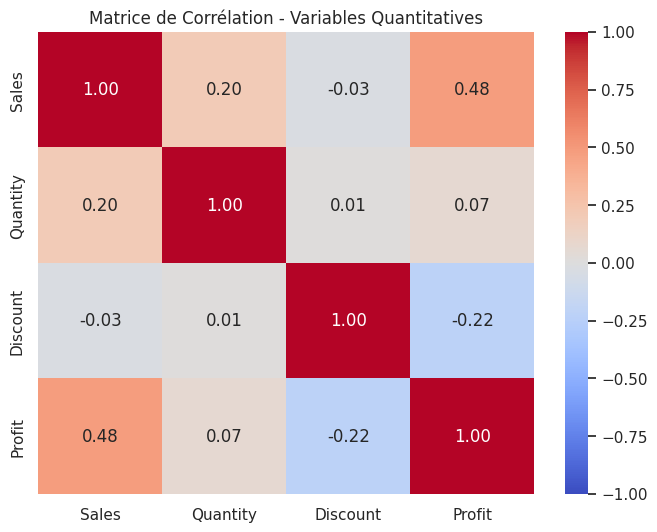

In [49]:
# Affichage de la Heatmap
plt.figure(figsize=(8, 6))
sns.heatmap(corr_matrix, annot=True, cmap='coolwarm', fmt=".2f", vmin=-1, vmax=1)
plt.title("Matrice de Corrélation - Variables Quantitatives")
plt.show()

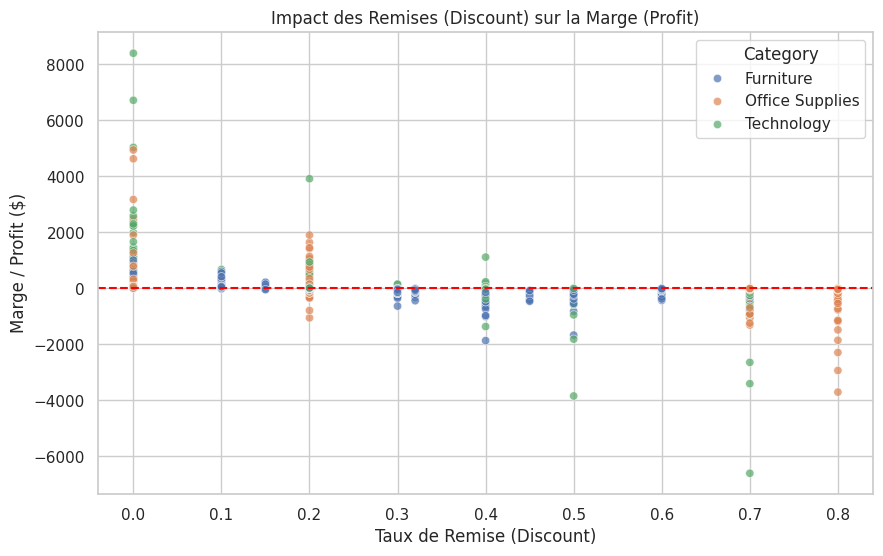

In [50]:
plt.figure(figsize=(10, 6))
sns.scatterplot(data=df, x='Discount', y='Profit', hue='Category', alpha=0.7)
plt.axhline(0, color='red', linestyle='--') # Ligne de rentabilité (Profit = 0)
plt.title("Impact des Remises (Discount) sur la Marge (Profit)")
plt.xlabel("Taux de Remise (Discount)")
plt.ylabel("Marge / Profit ($)")
plt.show()

In [51]:
# Comparaison des moyennes et sommes
profit_par_region = df.groupby('Region')[['Sales', 'Profit']].agg(['mean', 'sum'])
print("--- Performance par Région ---")
print(profit_par_region)

--- Performance par Région ---
              Sales                  Profit             
               mean          sum       mean          sum
Region                                                  
Central  215.772661  501239.8908  17.092709   39706.3625
East     238.336110  678781.2400  32.135808   91522.7800
South    241.803645  391721.9050  28.857673   46749.4303
West     226.493233  725457.8245  33.849032  108418.4489


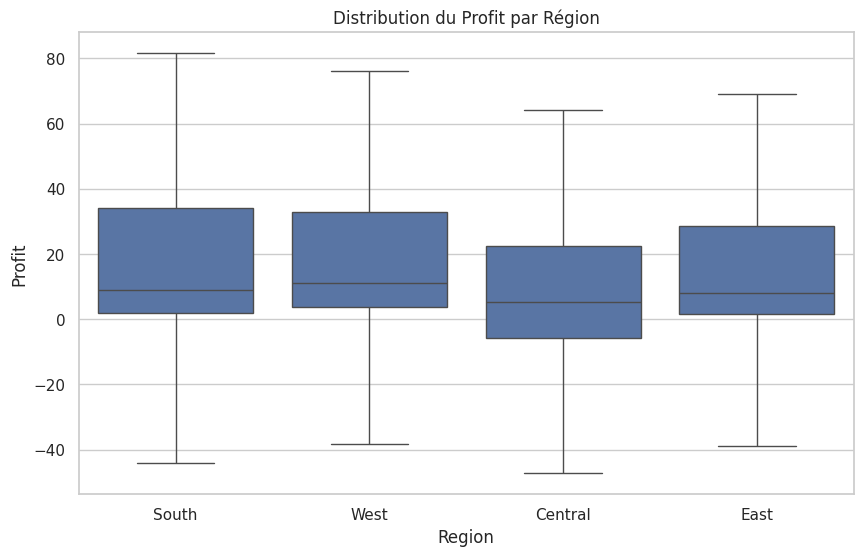

In [52]:
# Visualisation par Boxplot
plt.figure(figsize=(10, 6))
sns.boxplot(data=df, x='Region', y='Profit', showfliers=False) # Sans les valeurs extrêmes pour mieux voir la distribution
plt.title("Distribution du Profit par Région")
plt.show()

/tmp/ipykernel_2298/972823238.py:2: FutureWarning: 

The `ci` parameter is deprecated. Use `errorbar=None` for the same effect.

  sns.barplot(data=df, x='Sub-Category', y='Profit', estimator=np.mean, ci=None, palette="viridis")
/tmp/ipykernel_2298/972823238.py:2: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=df, x='Sub-Category', y='Profit', estimator=np.mean, ci=None, palette="viridis")


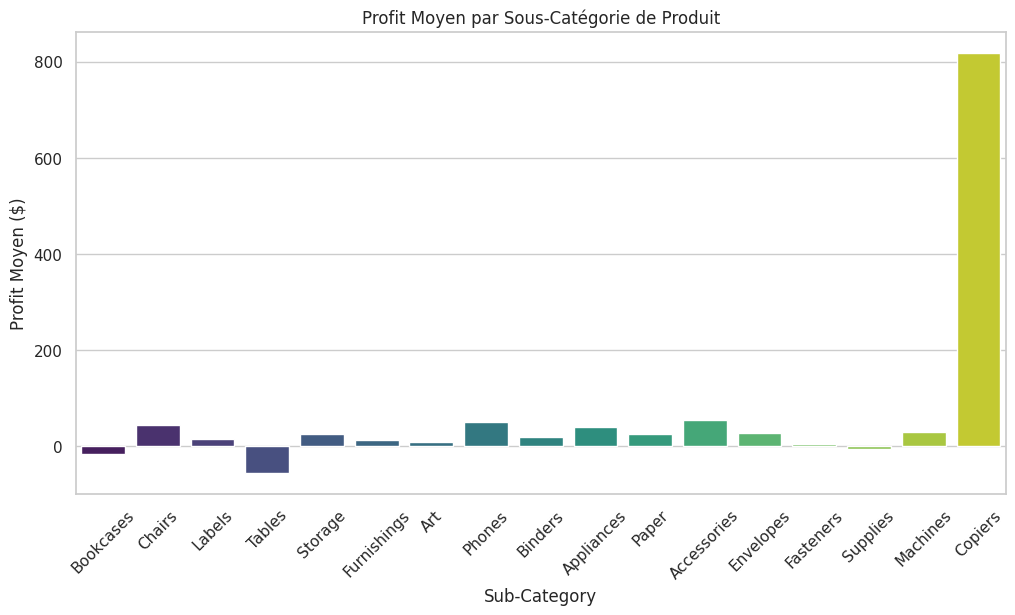

In [53]:
plt.figure(figsize=(12, 6))
sns.barplot(data=df, x='Sub-Category', y='Profit', estimator=np.mean, ci=None, palette="viridis")
plt.xticks(rotation=45)
plt.title("Profit Moyen par Sous-Catégorie de Produit")
plt.ylabel("Profit Moyen ($)")
plt.show()

In [54]:
# Tableau croisé en effectifs
tab_croise = pd.crosstab(df['Region'], df['Category'], margins=True)
print("--- Tableau Croisé : Région vs Catégorie ---")
print(tab_croise)

--- Tableau Croisé : Région vs Catégorie ---
Category  Furniture  Office Supplies  Technology   All
Region                                                
Central         481             1422         420  2323
East            601             1712         535  2848
South           332              995         293  1620
West            707             1897         599  3203
All            2121             6026        1847  9994


In [55]:
# Tableau croisé en pourcentages par ligne
tab_croise_pct = pd.crosstab(df['Region'], df['Category'], normalize='index') * 100
print("\n--- Répartition en % par Région ---")
print(tab_croise_pct.round(2))


--- Répartition en % par Région ---
Category  Furniture  Office Supplies  Technology
Region                                          
Central       20.71            61.21       18.08
East          21.10            60.11       18.79
South         20.49            61.42       18.09
West          22.07            59.23       18.70


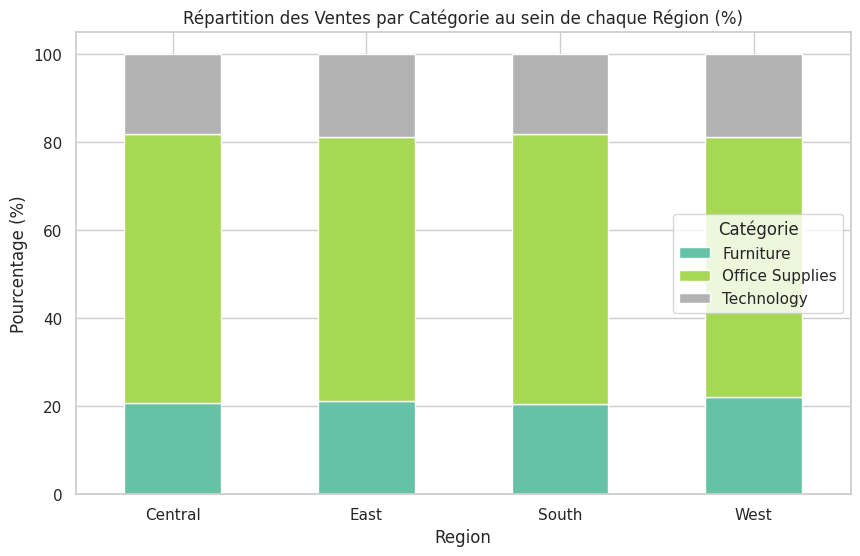

In [56]:
tab_croise_pct.plot(kind='bar', stacked=True, figsize=(10, 6), colormap='Set2')
plt.title("Répartition des Ventes par Catégorie au sein de chaque Région (%)")
plt.ylabel("Pourcentage (%)")
plt.legend(title="Catégorie")
plt.xticks(rotation=0)
plt.show()

In [57]:
# ANOVA : Comparaison du Profit entre les 4 Régions
regions = [group['Profit'].values for name, group in df.groupby('Region')]
f_stat, p_value = stats.f_oneway(*regions)

print("--- Test ANOVA (Profit par Région) ---")
print(f"Statistique F : {f_stat:.4f}")
print(f"p-value : {p_value:.4e}")

if p_value < 0.05:
    print("Conclusion : La différence de profit entre les régions est statistiquement SIGNIFICATIVE (p < 0.05).")
else:
    print("Conclusion : Aucune différence significative observée entre les régions.")

--- Test ANOVA (Profit par Région) ---
Statistique F : 2.6225
p-value : 4.8892e-02
Conclusion : La différence de profit entre les régions est statistiquement SIGNIFICATIVE (p < 0.05).


In [59]:
# Tableau croisé en effectifs
contingency_table = pd.crosstab(df['Region'], df['Category'])

# Test du Chi-2
chi2, p_val, dof, expected = stats.chi2_contingency(contingency_table)

print("\n--- Test du Chi-Deux (Région vs Catégorie) ---")
print(f"Statistique Chi2 : {chi2:.4f}")
print(f"p-value : {p_val:.4e}")

if p_val < 0.05:
    print("Conclusion : Il existe une relation SIGNIFICATIVE entre la Région et la Catégorie (p < 0.05).")
else:
    print("Conclusion : Les deux variables sont indépendantes.")


--- Test du Chi-Deux (Région vs Catégorie) ---
Statistique Chi2 : 3.6619
p-value : 7.2232e-01
Conclusion : Les deux variables sont indépendantes.


In [60]:
# Test de corrélation de Pearson
corr_coef, p_val_corr = stats.pearsonr(df['Discount'], df['Profit'])

print("\n--- Test de Corrélation (Discount vs Profit) ---")
print(f"Coefficient de corrélation r : {corr_coef:.4f}")
print(f"p-value : {p_val_corr:.4e}")

if p_val_corr < 0.05:
    print("Conclusion : L'impact négatif de la remise sur le profit est statistiquement SIGNIFICATIF.")


--- Test de Corrélation (Discount vs Profit) ---
Coefficient de corrélation r : -0.2195
p-value : 2.7023e-109
Conclusion : L'impact négatif de la remise sur le profit est statistiquement SIGNIFICATIF.
